# Лабораторна робота №1: Data Wrangling (Очищення, нормалізація та стандартизація даних)

**Мета роботи:** отримати навички очищення, нормалізації та стандартизації даних (підготовки даних).

---

## 1. Завантаження бібліотек та набору даних

Імпортуємо необхідні бібліотеки `pandas`, `numpy` та `matplotlib`, задамо список заголовків колонок та завантажимо «Автомобільний датасет» (`auto.csv`).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# URL датасету та локальний файл
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/Data%20files/auto.csv"
filename = "auto.csv" if os.path.exists("auto.csv") else url

headers = [
    "symboling", "normalized-losses", "make", "fuel-type", "aspiration",
    "num-of-doors", "body-style", "drive-wheels", "engine-location", "wheel-base",
    "length", "width", "height", "curb-weight", "engine-type",
    "num-of-cylinders", "engine-size", "fuel-system", "bore", "stroke",
    "compression-ratio", "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "price"
]

df = pd.read_csv(filename, names=headers)
print(f"Розмірність датасету: {df.shape[0]} рядків, {df.shape[1]} стовпців")
df.head(5)

Розмірність датасету: 205 рядків, 26 стовпців


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


## 2. Визначення та обробка відсутніх значень

У наборі даних автомобілів відсутні значення позначені знаком питання `"?"`. Замінимо `"?"` на `NaN` (`np.nan`) та підрахуємо кількість пропущених значень у кожному стовпці.

In [2]:
# Заміна "?" на NaN
df.replace("?", np.nan, inplace=True)
df.head(5)

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


In [3]:
# Оцінка на предмет відсутніх даних
missing_data = df.isnull()
missing_data.head(5)

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [4]:
# Підрахунок кількості відсутніх значень у кожному стовпці за допомогою циклу for
for column in missing_data.columns.values.tolist():
    na_count = missing_data[column].sum()
    if na_count > 0:
        print(f"Стовпець '{column}':")
        print(missing_data[column].value_counts())
        print("-" * 40)

Стовпець 'normalized-losses':
normalized-losses
False    164
True      41
Name: count, dtype: int64
----------------------------------------
Стовпець 'num-of-doors':
num-of-doors
False    203
True       2
Name: count, dtype: int64
----------------------------------------
Стовпець 'bore':
bore
False    201
True       4
Name: count, dtype: int64
----------------------------------------
Стовпець 'stroke':
stroke
False    201
True       4
Name: count, dtype: int64
----------------------------------------
Стовпець 'horsepower':
horsepower
False    203
True       2
Name: count, dtype: int64
----------------------------------------
Стовпець 'peak-rpm':
peak-rpm
False    203
True       2
Name: count, dtype: int64
----------------------------------------
Стовпець 'price':
price
False    201
True       4
Name: count, dtype: int64
----------------------------------------


Бачимо, що 7 стовпців містять пропущені значення (`NaN`):
1. `normalized-losses`: 41 пропущене значення
2. `num-of-doors`: 2 пропущених значення
3. `bore`: 4 пропущених значення
4. `stroke`: 4 пропущених значення
5. `horsepower`: 2 пропущених значення
6. `peak-rpm`: 2 пропущених значення
7. `price`: 4 пропущених значення

---

## 3. Заміна відсутніх даних (Завдання 1 та Завдання 4)

Спочатку виконаємо базові кроки з методичних вказівок для `normalized-losses` і `bore`, а потім виконаємо **Завдання 1** (заміна `NaN` у стовпці `stroke` середнім значенням) та **Завдання 4** (заміна всіх `NaN` у всіх стовпцях середнім значенням / модою для категоріальних).

In [5]:
# 1. Заміна NaN середнім значенням у стовпці 'normalized-losses'
avg_norm_loss = df["normalized-losses"].astype("float").mean(axis=0)
print("Average of normalized-losses:", avg_norm_loss)
df["normalized-losses"] = df["normalized-losses"].replace(np.nan, avg_norm_loss)

# 2. Заміна NaN середнім значенням у стовпці 'bore'
avg_bore = df["bore"].astype("float").mean(axis=0)
print("Average of bore:", avg_bore)
df["bore"] = df["bore"].replace(np.nan, avg_bore)

Average of normalized-losses: 122.0
Average of bore: 3.3297512437810943


### Завдання 1: Замініть `NaN` у стовпці `'stroke'` середнім значенням

In [6]:
# Обчислення середнього значення для стовпця 'stroke' та заміна NaN
avg_stroke = df["stroke"].astype("float").mean(axis=0)
print("Average of stroke:", avg_stroke)
df["stroke"] = df["stroke"].replace(np.nan, avg_stroke)
print("Кількість NaN у стовпці 'stroke' після заміни:", df["stroke"].isnull().sum())

Average of stroke: 3.255422885572139
Кількість NaN у стовпці 'stroke' після заміни: 0


### Завдання 4: Замініть усі `NaN` у всіх стовпцях середнім значенням

Замінимо `NaN` середнім значенням у всіх інших числових стовпцях (`horsepower`, `peak-rpm`, `price`), а для текстового (категоріального) стовпця `num-of-doors` замінимо пропуски найчастішим значенням (модою `'four'`).

*(Примітка: для задач моделювання ціни в наступних лабораторних роботах ми також збережемо чистий датасет, де всі дані мають коректні типи).*

In [7]:
# Заміна NaN середнім значенням у 'horsepower'
avg_horsepower = df["horsepower"].astype("float").mean(axis=0)
print("Average horsepower:", avg_horsepower)
df["horsepower"] = df["horsepower"].replace(np.nan, avg_horsepower)

# Заміна NaN середнім значенням у 'peak-rpm'
avg_peakrpm = df["peak-rpm"].astype("float").mean(axis=0)
print("Average peak-rpm:", avg_peakrpm)
df["peak-rpm"] = df["peak-rpm"].replace(np.nan, avg_peakrpm)

# Заміна NaN середнім значенням у 'price' (згідно з умовою Завдання 4)
avg_price = df["price"].astype("float").mean(axis=0)
print("Average price:", avg_price)
df["price"] = df["price"].replace(np.nan, avg_price)

# Для категоріального стовпця 'num-of-doors' використовуємо найчастіше значення (моду)
most_freq_doors = df["num-of-doors"].value_counts().idxmax()
print("Most frequent num-of-doors:", most_freq_doors)
df["num-of-doors"] = df["num-of-doors"].replace(np.nan, most_freq_doors)

print("\nЗагальна кількість пропущених значень (NaN) у датафреймі:", df.isnull().sum().sum())

Average horsepower: 104.25615763546799
Average peak-rpm: 5125.369458128079
Average price: 13207.129353233831
Most frequent num-of-doors: four

Загальна кількість пропущених значень (NaN) у датафреймі: 0


## 4. Коректування формату даних

Перевіримо типи даних стовпців за допомогою `.dtypes` та приведемо їх до відповідних числових форматів (`float`, `int`).

In [8]:
# Перетворення типів даних у правильний формат
df[["bore", "stroke"]] = df[["bore", "stroke"]].astype("float")
df[["normalized-losses"]] = df[["normalized-losses"]].astype("int")
df[["price"]] = df[["price"]].astype("float")
df[["peak-rpm"]] = df[["peak-rpm"]].astype("float")
df["horsepower"] = df["horsepower"].astype("int")

df.dtypes

symboling              int64
normalized-losses      int64
make                  object
fuel-type             object
aspiration            object
num-of-doors          object
body-style            object
drive-wheels          object
engine-location       object
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type           object
num-of-cylinders      object
engine-size            int64
fuel-system           object
bore                 float64
stroke               float64
compression-ratio    float64
horsepower             int64
peak-rpm             float64
city-mpg               int64
highway-mpg            int64
price                float64

## 5. Стандартизація та Нормалізація даних (Завдання 2)

### Стандартизація даних
Перетворимо витрату пального з миль на галон (`mpg`) у літри на 100 км (`L/100km`) за формулою:
$$\text{L/100km} = \frac{235}{\text{mpg}}$$

In [9]:
df["city-L/100km"] = 235 / df["city-mpg"]
df["highway-L/100km"] = 235 / df["highway-mpg"]
df[["city-mpg", "city-L/100km", "highway-mpg", "highway-L/100km"]].head()

,city-mpg,city-L/100km,highway-mpg,highway-L/100km
0,21,11.190476,27,8.703704
1,21,11.190476,27,8.703704
2,19,12.368421,26,9.038462
3,24,9.791667,30,7.833333
4,18,13.055556,22,10.681818


### Завдання 2: Нормалізуйте стовпець `'height'`

Нормалізуємо стовпці `length`, `width` та **`height`** методом простого масштабування ознак (*Simple Feature Scaling*):
$$x_{\text{new}} = \frac{x_{\text{old}}}{x_{\max}}$$
щоб значення лежали в діапазоні від $0$ до $1$.

In [10]:
# Нормалізація length, width та height (Завдання 2)
df["length"] = df["length"] / df["length"].max()
df["width"] = df["width"] / df["width"].max()
df["height"] = df["height"] / df["height"].max()

# Перевіримо нормалізовані стовпці
df[["length", "width", "height"]].head(10)

,length,width,height
0,0.811148,0.886584,0.816054
1,0.811148,0.886584,0.816054
2,0.822681,0.905947,0.876254
3,0.848630,0.915629,0.908027
4,0.848630,0.918396,0.908027
5,0.851994,0.917012,0.887960
6,0.925997,0.987552,0.931438
7,0.925997,0.987552,0.931438
8,0.925997,0.987552,0.934783
9,0.856319,0.939142,0.869565


## 6. Бінінг (Binning)

Розділимо неперервну змінну `horsepower` (потужність) на 3 дискретні категорії («біни»): `Low` (мала), `Medium` (середня) та `High` (висока) за допомогою `np.linspace` та `pd.cut`.

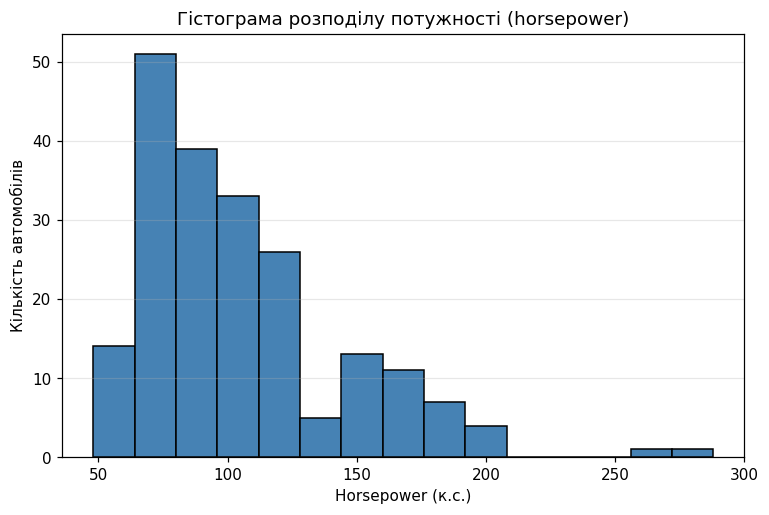

In [11]:
# Візуалізація розподілу потужності (horsepower) до бінінгу
plt.figure(figsize=(8, 5))
plt.hist(df["horsepower"], bins=15, color="steelblue", edgecolor="black")
plt.xlabel("Horsepower (к.с.)")
plt.ylabel("Кількість автомобілів")
plt.title("Гістограма розподілу потужності (horsepower)")
plt.grid(axis="y", alpha=0.3)
plt.show()

Межі бінів: [ 48. 128. 208. 288.]

Розподіл за категоріями потужності:
horsepower-binned
Low       163
Medium     40
High        2
Name: count, dtype: int64


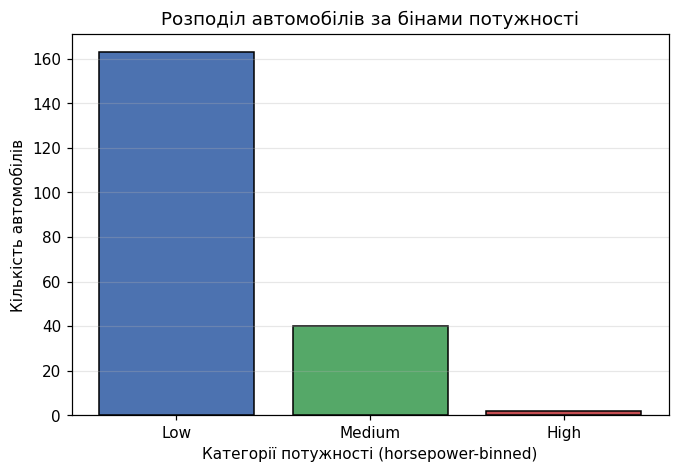

In [12]:
# Створення 3 бінів однакової ширини
bins = np.linspace(min(df["horsepower"]), max(df["horsepower"]), 4)
print("Межі бінів:", bins)

group_names = ["Low", "Medium", "High"]
df["horsepower-binned"] = pd.cut(df["horsepower"], bins, labels=group_names, include_lowest=True)

print("\nРозподіл за категоріями потужності:")
print(df["horsepower-binned"].value_counts())

plt.figure(figsize=(7, 4.5))
plt.bar(group_names, df["horsepower-binned"].value_counts()[group_names], color=["#4c72b0", "#55a868", "#c44e52"], edgecolor="black")
plt.xlabel("Категорії потужності (horsepower-binned)")
plt.ylabel("Кількість автомобілів")
plt.title("Розподіл автомобілів за бінами потужності")
plt.grid(axis="y", alpha=0.3)
plt.show()

## 7. Індикаторні змінні (Завдання 3.1 та 3.2)

Індикаторна змінна (*dummy variable*) — це числова змінна ($0$ або $1$), яка використовується для позначення категорій.

Спочатку створимо індикаторну змінну для стовпця `fuel-type`, а потім виконаємо **Завдання 3.1** та **Завдання 3.2** для стовпця `'aspiration'`.

In [13]:
# Індикаторна змінна для 'fuel-type'
dummy_variable_1 = pd.get_dummies(df["fuel-type"], dtype=int)
dummy_variable_1.rename(columns={"gas": "fuel-type-gas", "diesel": "fuel-type-diesel"}, inplace=True)
df = pd.concat([df, dummy_variable_1], axis=1)
df.drop("fuel-type", axis=1, inplace=True)
dummy_variable_1.head()

,fuel-type-diesel,fuel-type-gas
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1


### Завдання 3.1: Створіть змінну індикатора для стовпця `'aspiration'`

In [14]:
# Отримання індикаторних змінних для стовпця 'aspiration'
dummy_variable_2 = pd.get_dummies(df["aspiration"], dtype=int)

# Перейменування стовпців для зрозумілості
dummy_variable_2.rename(columns={"std": "aspiration-std", "turbo": "aspiration-turbo"}, inplace=True)
dummy_variable_2.head()

,aspiration-std,aspiration-turbo
0,1,0
1,1,0
2,1,0
3,1,0
4,1,0


### Завдання 3.2: Об’єднайте новий фрейм даних із вихідним фреймом даних, а потім видаліть стовпець `'aspiration'`

In [15]:
# Об'єднання нового фрейму даних із вихідним фреймом даних
df = pd.concat([df, dummy_variable_2], axis=1)

# Видалення вихідного стовпця 'aspiration'
df.drop("aspiration", axis=1, inplace=True)

# Збереження очищеного датасету у CSV файл
df.to_csv("clean_df_lab1.csv", index=False)
print("Стовпець 'aspiration' присутній у df?", "aspiration" in df.columns)
df[["make", "aspiration-std", "aspiration-turbo", "price"]].head(10)

Стовпець 'aspiration' присутній у df? False


,make,aspiration-std,aspiration-turbo,price
0,alfa-romero,1,0,13495.000000
1,alfa-romero,1,0,16500.000000
2,alfa-romero,1,0,16500.000000
3,audi,1,0,13950.000000
4,audi,1,0,17450.000000
5,audi,1,0,15250.000000
6,audi,1,0,17710.000000
7,audi,1,0,18920.000000
8,audi,0,1,23875.000000
9,audi,0,1,13207.129353


---

## 8. Контрольні запитання

### 1. Що таке стандартизація?
**Стандартизація** — це процес приведення даних, зібраних із різних джерел та у різних одиницях вимірювання чи форматах, до єдиного загального формату, що дозволяє проводити коректне та змістовне порівняння (наприклад, переведення витрати пального з миль на галон `mpg` у літри на 100 км `L/100km`). Також у статистиці та машинному навчанні під стандартизацією (Z-score standardization) розуміють перетворення числової змінної, за якого від кожного значення віднімають середнє арифметичне $\mu$ і ділять на стандартне відхилення $\sigma$:
$$z = \frac{x - \mu}{\sigma}$$
У результаті змінна має середнє значення $0$ та дисперсію (і стандартне відхилення) $1$.

### 2. Що таке нормалізація?
**Нормалізація** — це процес масштабування числових значень кількох змінних у подібний (зазвичай обмежений) числовий діапазон, найчастіше $[0, 1]$ або $[-1, 1]$. Це необхідно для того, щоб ознаки з великими абсолютними значеннями не домінували над ознаками з малими значеннями під час навчання моделей (наприклад, у лінійній регресії або методах градієнтного спуску).

### 3. Якими способами можна позбутись відсутності даних?
Існують два основні підходи до обробки пропущених значень (`NaN`):
1. **Видалення даних**:
   - *Видалення всього рядка (спостереження)* — застосовується, коли відсутнє значення цільової змінної (наприклад, `price`), або коли пропусків дуже мало.
   - *Видалення всього стовпця (ознаки)* — застосовується лише тоді, коли більшість записів у стовпці порожні і змінна не несе достатньо інформації.
2. **Заміна (імпутація) даних**:
   - *Заміна на середнє значення (mean) або медіану (median)* — використовується для неперервних числових змінних (`normalized-losses`, `bore`, `stroke`, `horsepower`, `peak-rpm`).
   - *Заміна за частотою (модою / найчастішим значенням)* — використовується для категоріальних змінних (наприклад, заміна пропущеної кількості дверей `num-of-doors` на `'four'`).
   - *Заміна за допомогою інших функцій / моделей* — інтерполяція, регресійна імпутація або прогнозування за іншими ознаками.

### 4. Що таке бінінг?
**Бінінг (Binning / дискретизація)** — це процес перетворення неперервних числових змінних у дискретні категоріальні інтервали («біни» або «кошики») для згрупованого аналізу, зменшення впливу шуму/викидів або кращої візуалізації (наприклад, поділ неперервної потужності двигуна `horsepower` на три категорії: `Low`, `Medium`, `High`).

### 5. Як нормалізувати дані?
Найпоширеніші математичні способи нормалізації даних:
1. **Просте масштабування ознак (Simple Feature Scaling)**: ділення кожного значення на максимальне значення стовпця:
   $$x_{\text{new}} = \frac{x_{\text{old}}}{x_{\max}}$$
2. **Min-Max нормалізація**: лінійне перетворення значень у діапазон $[0, 1]$:
   $$x_{\text{new}} = \frac{x_{\text{old}} - x_{\min}}{x_{\max} - x_{\min}}$$
3. **Стандартизація (Z-score нормалізація)**: центрування відносно середнього значення $\mu$ та масштабування на стандартне відхилення $\sigma$:
   $$x_{\text{new}} = \frac{x_{\text{old}} - \mu}{\sigma}$$